# Imports

## Importing Libraries

In [1]:
# Import libraries, silence warnings, and set the low-resource settings used throughout (2 CPU threads, fixed seed, 5 folds).
import warnings
warnings.filterwarnings('ignore')
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from scipy.stats import spearmanr
from pandas.io.stata import StataReader
from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, roc_curve, precision_recall_curve
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

RANDOM_STATE = 42
N_JOBS = 2            # CPU threads per model; lower to 1 on a very slow laptop
N_SPLITS = 5          # cross-validation folds
SHAP_N_PER_FOLD = 1000  # held-out rows explained per fold; lower to 500 if SHAP is slow
os.makedirs('figures', exist_ok=True)
os.makedirs('outputs', exist_ok=True)
plt.rcParams.update({'figure.dpi': 100, 'axes.spines.top': False, 'axes.spines.right': False})

## Load and Clean Data

In [2]:
# Load the Stata dataset, extract variable labels, and drop missing survey design or outcome records.
data = pd.read_stata("MICS-child-ISRC.dta", convert_categoricals=False)
stata_file = StataReader("MICS-child-ISRC.dta")
variable_labels = stata_file.variable_labels()
survey_cols = ['hh1', 'chweight', 'strata', 'severe_wasting']
df_clean = data.dropna(subset=survey_cols).copy()
df_clean = df_clean[df_clean['chweight'] > 0].reset_index(drop=True)

In [3]:
# Drop the columns derived from the same weight-for-height measurement as the outcome to prevent target leakage.
dropped_cols = ['whz2', 'mod_wasting', 'any_wasting', 'wast_cat']
df_clean = df_clean.drop(columns=dropped_cols, errors='ignore').copy()
print(df_clean.shape, '| severe wasting cases:', int(df_clean.severe_wasting.sum()), f'({df_clean.severe_wasting.mean()*100:.2f}%)')

(22311, 45) | severe wasting cases: 552 (2.47%)


# Feature Sets

Two prediction problems are run, because the feeding and antenatal-care variables exist only for children aged 0-1 (completed years, i.e. under 2):

- **Analysis A, all children aged 0-4:** child, maternal, and household predictors only.
- **Analysis B, children aged 0-1:** the Analysis A predictors plus dietary diversity, the seven food groups, breastfeeding, bottle feeding, and antenatal care.

Excluded on purpose: identifiers and design variables (`hh1`, `hh2`, `ln`, `child_id`, `mother_id`, `hh_id`, `hh7a`, `strata`, `chweight`, `has_mother`); the four outcome-derived columns dropped above; and columns that repeat another predictor (`young` repeats `ub2`; `any_illness` repeats the three illness variables; `mage_cat` and `parity_cat` repeat `wb4` and `cm11`; `fvs` overlaps `dds`; `bd9` is missing for 27% of children even at ages 0-1). `dds` is the sum of the seven food-group indicators, so SHAP importance is shared between them. Categories are used as integer codes and missing values are left as they are (the tree models handle them natively, so no rows are dropped).

In [4]:
# Define the Analysis A (all children) and Analysis B (ages 0-1) predictor lists and the outcome.
features_all = [
    'ub2', 'female', 'urban', 'division', 'wealth', 'edu_level', 'wb4', 'cm11', 'mother_married',
    'water_cat', 'toilet_cat', 'fuel_cat', 'electricity', 'insured',
    'diarrhoea_2w', 'cough_2w', 'breathing_2w'
]
features_infant = features_all + [
    'dds', 'fg_grain', 'fg_legume', 'fg_dairy', 'fg_flesh', 'fg_egg', 'fg_vita', 'fg_ofv',
    'bf_status', 'bottle', 'anc_cat'
]
target = 'severe_wasting'

df_all = df_clean.copy()
df_infant = df_clean[df_clean['young'] == 1].copy()

X_all = df_all[features_all].astype('float32');       y_all = df_all[target].astype(int).to_numpy();       g_all = df_all['hh1'].to_numpy()
X_inf = df_infant[features_infant].astype('float32'); y_inf = df_infant[target].astype(int).to_numpy();    g_inf = df_infant['hh1'].to_numpy()

print(f'Analysis A: {X_all.shape[0]:,} children, {X_all.shape[1]} predictors, {y_all.sum()} cases ({y_all.mean()*100:.2f}%)')
print(f'Analysis B: {X_inf.shape[0]:,} children, {X_inf.shape[1]} predictors, {y_inf.sum()} cases ({y_inf.mean()*100:.2f}%)')
miss = pd.concat([X_all.isna().mean().mul(100).round(2).rename('A: % missing'), X_inf.isna().mean().mul(100).round(2).rename('B: % missing')], axis=1)
print(miss[(miss.fillna(0) > 0).any(axis=1)].to_string())

Analysis A: 22,311 children, 17 predictors, 552 cases (2.47%)
Analysis B: 8,888 children, 28 predictors, 297 cases (3.34%)
                A: % missing  B: % missing
edu_level               1.18          0.39
wb4                     1.16          0.36
cm11                    1.20          0.38
mother_married          1.09          0.32
insured                 1.17          0.36
diarrhoea_2w            0.04          0.03
cough_2w                0.04          0.06
breathing_2w            0.03          0.02
dds                      NaN          0.82
fg_grain                 NaN          0.07
fg_legume                NaN          0.03
fg_dairy                 NaN          0.25
fg_flesh                 NaN          0.16
fg_egg                   NaN          0.12
fg_vita                  NaN          0.10
fg_ofv                   NaN          0.28
bf_status                NaN          0.03
bottle                   NaN          0.02
anc_cat                  NaN          1.01


# Cross-Validation Setup

Children in the same cluster (PSU, `hh1`) share a neighbourhood, so a plain random split would put near-identical children in both the training and test folds and inflate the scores. **Stratified group 5-fold cross-validation** keeps every PSU entirely inside one fold and keeps the share of severe cases similar across folds. Every child is predicted exactly once by a model that never saw their PSU (out-of-fold predictions). Models are trained unweighted because the goal is to predict risk in this sample, not to estimate population totals.

In [5]:
# Build the grouped, stratified cross-validation splitter and check fold sizes, case counts and PSU separation.
cv = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)

def fold_table(X, y, groups):
    rows = []
    for k, (tr, te) in enumerate(cv.split(X, y, groups), 1):
        rows.append({'fold': k, 'train_n': len(tr), 'test_n': len(te), 'test_cases': int(y[te].sum()),
                     'test_case_%': round(y[te].mean() * 100, 2), 'PSUs_shared': len(set(groups[tr]) & set(groups[te]))})
    return pd.DataFrame(rows)

print('Analysis A folds'); print(fold_table(X_all, y_all, g_all).to_string(index=False))
print('\nAnalysis B folds'); print(fold_table(X_inf, y_inf, g_inf).to_string(index=False))

Analysis A folds


 fold  train_n  test_n  test_cases  test_case_%  PSUs_shared
    1    17848    4463         111         2.49            0
    2    17849    4462         110         2.47            0
    3    17847    4464         111         2.49            0
    4    17849    4462         110         2.47            0
    5    17851    4460         110         2.47            0

Analysis B folds


 fold  train_n  test_n  test_cases  test_case_%  PSUs_shared
    1     7110    1778          60         3.37            0
    2     7110    1778          60         3.37            0
    3     7110    1778          59         3.32            0
    4     7112    1776          59         3.32            0
    5     7110    1778          59         3.32            0


# Models

Four tree-based classifiers are used **with their default settings** (no hyperparameter tuning). Only resource and reproducibility options are set: a fixed `random_state`, `n_jobs=2`, and silent logging. The default decision tree is grown until its leaves are pure, so it is expected to overfit; the contrast with the ensembles is part of the comparison.

In [6]:
# Define the four raw (untuned) tree-based models; only seed, thread count and log level are set.
def make_models():
    return {
        'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE),
        'Random Forest': RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=N_JOBS),
        'XGBoost': XGBClassifier(random_state=RANDOM_STATE, n_jobs=N_JOBS, eval_metric='logloss'),
        'LightGBM': LGBMClassifier(random_state=RANDOM_STATE, n_jobs=N_JOBS, verbose=-1),
    }
models = make_models()
for name, m in models.items():
    print(f'{name:14s} {type(m).__name__}')

Decision Tree  DecisionTreeClassifier
Random Forest  RandomForestClassifier
XGBoost        XGBClassifier
LightGBM       LGBMClassifier


# Prediction Analysis A: All Children (Ages 0-4)

## Cross-Validated Results

In [7]:
# Define helpers that fit each model in every fold and record ROC AUC, PR AUC, Brier score, top-decile capture, train AUC and fit time.
metric_cols = ['roc_auc', 'pr_auc', 'brier', 'top10_capture', 'train_auc', 'fit_seconds']

def cv_evaluate(X, y, groups, models):
    rng = np.random.RandomState(RANDOM_STATE)
    fold_rows, curves, oof = [], {}, {}
    for name, base in models.items():
        oof[name] = np.zeros(len(y)); curves[name] = []
        for k, (tr, te) in enumerate(cv.split(X, y, groups), 1):
            model = clone(base)
            t0 = time.time(); model.fit(X.iloc[tr], y[tr]); fit_s = time.time() - t0
            p_te = model.predict_proba(X.iloc[te])[:, 1]
            p_tr = model.predict_proba(X.iloc[tr])[:, 1]
            oof[name][te] = p_te
            fpr, tpr, _ = roc_curve(y[te], p_te); curves[name].append((fpr, tpr))
            # Share of the fold's cases found in the 10% of children with the highest predicted risk (ties broken at random).
            top = np.argsort(-(p_te + rng.uniform(0, 1e-9, len(p_te))))[:int(np.ceil(0.10 * len(te)))]
            fold_rows.append({'model': name, 'fold': k, 'roc_auc': roc_auc_score(y[te], p_te),
                              'pr_auc': average_precision_score(y[te], p_te), 'brier': brier_score_loss(y[te], p_te),
                              'top10_capture': y[te][top].sum() / y[te].sum(), 'train_auc': roc_auc_score(y[tr], p_tr),
                              'fit_seconds': fit_s})
    return pd.DataFrame(fold_rows), curves, oof

def summarize(fold_df, y, oof):
    g = fold_df.groupby('model')[metric_cols].agg(['mean', 'std'])
    out = pd.DataFrame(index=g.index)
    for c, label in [('roc_auc', 'ROC AUC'), ('pr_auc', 'PR AUC'), ('brier', 'Brier'), ('top10_capture', 'Top-10% capture'), ('train_auc', 'Train ROC AUC')]:
        out[label] = [f'{g.loc[i, (c, "mean")]:.3f} ± {g.loc[i, (c, "std")]:.3f}' for i in g.index]
    out['Pooled OOF ROC AUC'] = [round(roc_auc_score(y, oof[i]), 3) for i in g.index]
    out['Fit time (s)'] = [round(g.loc[i, ('fit_seconds', 'mean')], 1) for i in g.index]
    out['_sort'] = g[('roc_auc', 'mean')]
    return out.sort_values('_sort', ascending=False).drop(columns='_sort')

def baseline_text(y):
    p = y.mean()
    return f'No-skill reference: ROC AUC 0.500 | PR AUC {p:.3f} (= prevalence) | Brier {p*(1-p):.4f} | Top-10% capture 0.100'

In [8]:
# Run 5-fold grouped cross-validation for the four raw models on all children and print the summary table.
t0 = time.time()
fold_all, curves_all, oof_all = cv_evaluate(X_all, y_all, g_all, make_models())
summary_all = summarize(fold_all, y_all, oof_all)
print(f'Finished in {time.time() - t0:.0f} s\n')
print(summary_all.to_string()); print('\n' + baseline_text(y_all))
fold_all.to_csv('outputs/ml_cv_fold_metrics_all_children.csv', index=False)
summary_all.to_csv('outputs/ml_cv_summary_all_children.csv')

Finished in 16 s

                     ROC AUC         PR AUC          Brier Top-10% capture  Train ROC AUC  Pooled OOF ROC AUC  Fit time (s)
model                                                                                                                      
LightGBM       0.542 ± 0.031  0.033 ± 0.005  0.025 ± 0.000   0.138 ± 0.012  0.966 ± 0.005               0.542           0.3
Random Forest  0.534 ± 0.021  0.028 ± 0.001  0.026 ± 0.000   0.120 ± 0.010  1.000 ± 0.000               0.534           1.5
XGBoost        0.526 ± 0.023  0.032 ± 0.006  0.025 ± 0.000   0.131 ± 0.027  0.984 ± 0.003               0.526           0.2
Decision Tree  0.503 ± 0.007  0.025 ± 0.001  0.062 ± 0.004   0.114 ± 0.032  1.000 ± 0.000               0.503           0.1

No-skill reference: ROC AUC 0.500 | PR AUC 0.025 (= prevalence) | Brier 0.0241 | Top-10% capture 0.100


In [9]:
# Show the fold-by-fold ROC AUC for each model to see how stable the scores are.
print(fold_all.pivot(index='fold', columns='model', values='roc_auc').round(3).to_string())

model  Decision Tree  LightGBM  Random Forest  XGBoost
fold                                                  
1              0.512     0.511          0.510    0.520
2              0.509     0.533          0.532    0.521
3              0.494     0.538          0.519    0.514
4              0.498     0.534          0.549    0.508
5              0.501     0.595          0.561    0.567


## ROC Curves

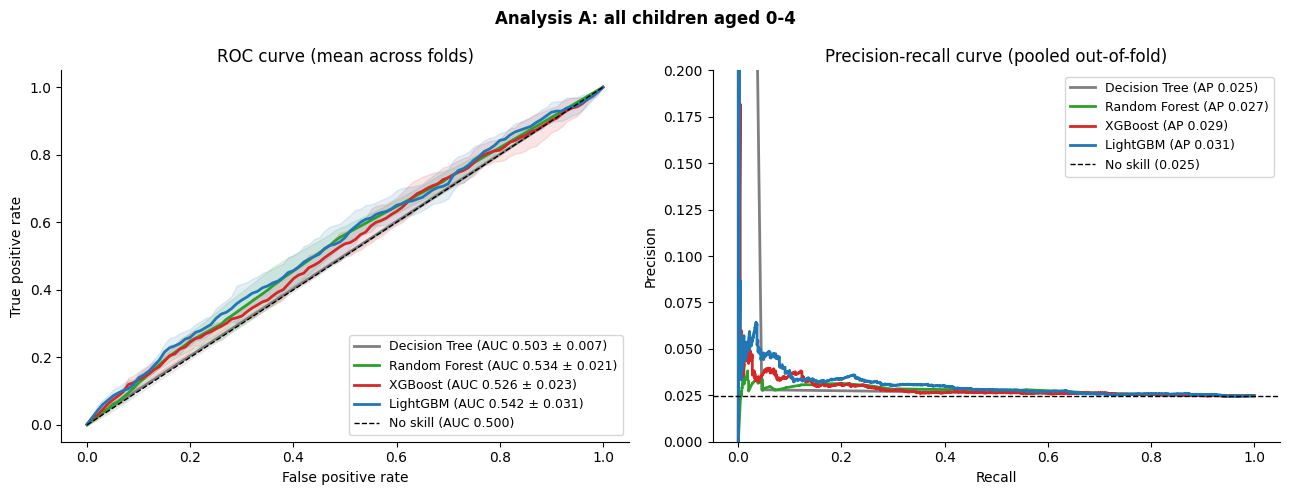

In [10]:
# Plot the mean ROC curve (with +/-1 SD across folds) and the pooled out-of-fold precision-recall curve for all four models.
colors = {'Decision Tree': '#7f7f7f', 'Random Forest': '#2ca02c', 'XGBoost': '#d62728', 'LightGBM': '#1f77b4'}

def plot_roc_pr(fold_df, curves, oof, y, title, path):
    grid = np.linspace(0, 1, 101)
    fig, ax = plt.subplots(1, 2, figsize=(13, 5))
    for name in curves:
        tprs = np.array([np.interp(grid, f, t) for f, t in curves[name]]); mean, sd = tprs.mean(0), tprs.std(0)
        a = fold_df[fold_df.model == name].roc_auc
        ax[0].plot(grid, mean, color=colors[name], lw=2, label=f'{name} (AUC {a.mean():.3f} ± {a.std():.3f})')
        ax[0].fill_between(grid, np.clip(mean - sd, 0, 1), np.clip(mean + sd, 0, 1), color=colors[name], alpha=.12)
        pr, rc, _ = precision_recall_curve(y, oof[name])
        ax[1].plot(rc, pr, color=colors[name], lw=2, label=f'{name} (AP {average_precision_score(y, oof[name]):.3f})')
    ax[0].plot([0, 1], [0, 1], 'k--', lw=1, label='No skill (AUC 0.500)')
    ax[0].set_xlabel('False positive rate'); ax[0].set_ylabel('True positive rate'); ax[0].set_title('ROC curve (mean across folds)'); ax[0].legend(loc='lower right', fontsize=9)
    ax[1].axhline(y.mean(), color='k', ls='--', lw=1, label=f'No skill ({y.mean():.3f})')
    ax[1].set_xlabel('Recall'); ax[1].set_ylabel('Precision'); ax[1].set_title('Precision-recall curve (pooled out-of-fold)'); ax[1].set_ylim(0, max(.2, y.mean() * 4)); ax[1].legend(fontsize=9)
    fig.suptitle(title, fontweight='bold'); plt.tight_layout(); plt.savefig(path, dpi=110, bbox_inches='tight'); plt.show()

plot_roc_pr(fold_all, curves_all, oof_all, y_all, 'Analysis A: all children aged 0-4', 'figures/ml_roc_pr_all_children.png')

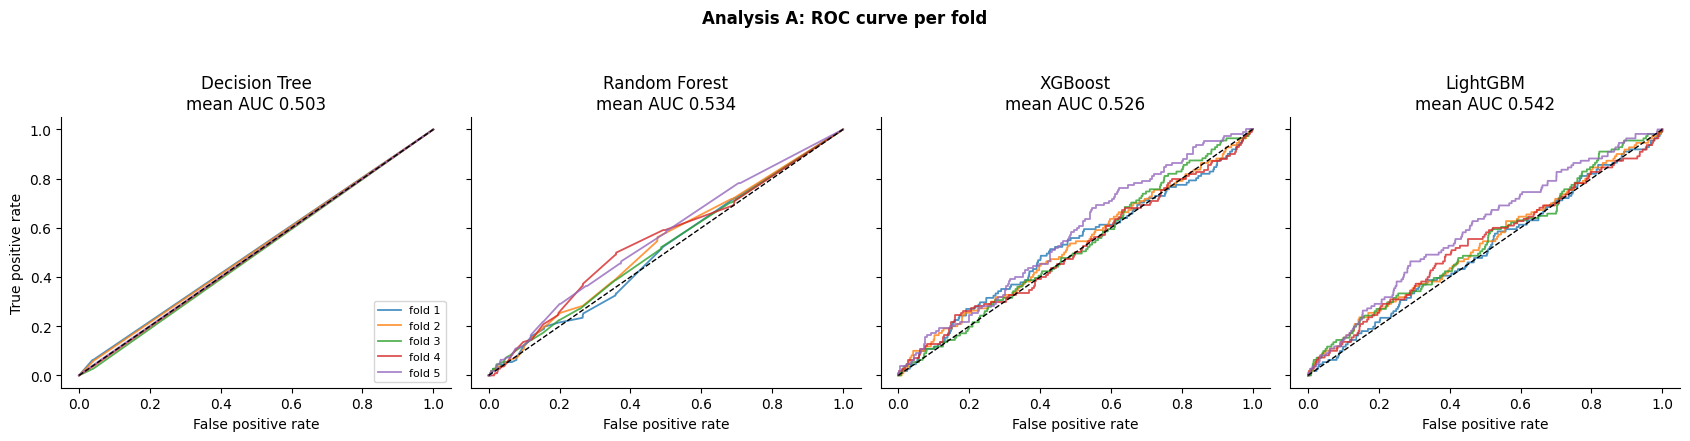

In [11]:
# Plot the ROC curve of every fold for each model to show fold-to-fold variability.
def plot_fold_roc(fold_df, curves, title, path):
    fig, axes = plt.subplots(1, 4, figsize=(17, 4.2), sharey=True)
    for ax, name in zip(axes, curves):
        for k, (f, t) in enumerate(curves[name], 1):
            ax.plot(f, t, lw=1.3, alpha=.8, label=f'fold {k}')
        ax.plot([0, 1], [0, 1], 'k--', lw=1); ax.set_title(f'{name}\nmean AUC {fold_df[fold_df.model == name].roc_auc.mean():.3f}'); ax.set_xlabel('False positive rate')
    axes[0].set_ylabel('True positive rate'); axes[0].legend(fontsize=8, loc='lower right')
    fig.suptitle(title, fontweight='bold', y=1.04); plt.tight_layout(); plt.savefig(path, dpi=110, bbox_inches='tight'); plt.show()

plot_fold_roc(fold_all, curves_all, 'Analysis A: ROC curve per fold', 'figures/ml_roc_folds_all_children.png')

# Prediction Analysis B: Children Aged 0-1 With Feeding and ANC Variables

## Cross-Validated Results

In [12]:
# Run 5-fold grouped cross-validation for the four raw models on children aged 0-1 using the feeding and ANC predictors.
t0 = time.time()
fold_inf, curves_inf, oof_inf = cv_evaluate(X_inf, y_inf, g_inf, make_models())
summary_inf = summarize(fold_inf, y_inf, oof_inf)
print(f'Finished in {time.time() - t0:.0f} s\n')
print(summary_inf.to_string()); print('\n' + baseline_text(y_inf))
print('\nFold-by-fold ROC AUC'); print(fold_inf.pivot(index='fold', columns='model', values='roc_auc').round(3).to_string())
fold_inf.to_csv('outputs/ml_cv_fold_metrics_infants.csv', index=False)
summary_inf.to_csv('outputs/ml_cv_summary_infants.csv')

Finished in 10 s

                     ROC AUC         PR AUC          Brier Top-10% capture  Train ROC AUC  Pooled OOF ROC AUC  Fit time (s)
model                                                                                                                      
XGBoost        0.552 ± 0.044  0.045 ± 0.012  0.035 ± 0.001   0.145 ± 0.039  1.000 ± 0.000               0.551           0.1
Random Forest  0.547 ± 0.042  0.048 ± 0.018  0.034 ± 0.001   0.131 ± 0.057  1.000 ± 0.000               0.547           0.7
LightGBM       0.544 ± 0.025  0.047 ± 0.008  0.033 ± 0.000   0.128 ± 0.025  0.998 ± 0.001               0.544           0.2
Decision Tree  0.503 ± 0.012  0.034 ± 0.001  0.075 ± 0.002   0.118 ± 0.048  0.999 ± 0.002               0.503           0.0

No-skill reference: ROC AUC 0.500 | PR AUC 0.033 (= prevalence) | Brier 0.0323 | Top-10% capture 0.100

Fold-by-fold ROC AUC
model  Decision Tree  LightGBM  Random Forest  XGBoost
fold                                                  
1 

## ROC Curves

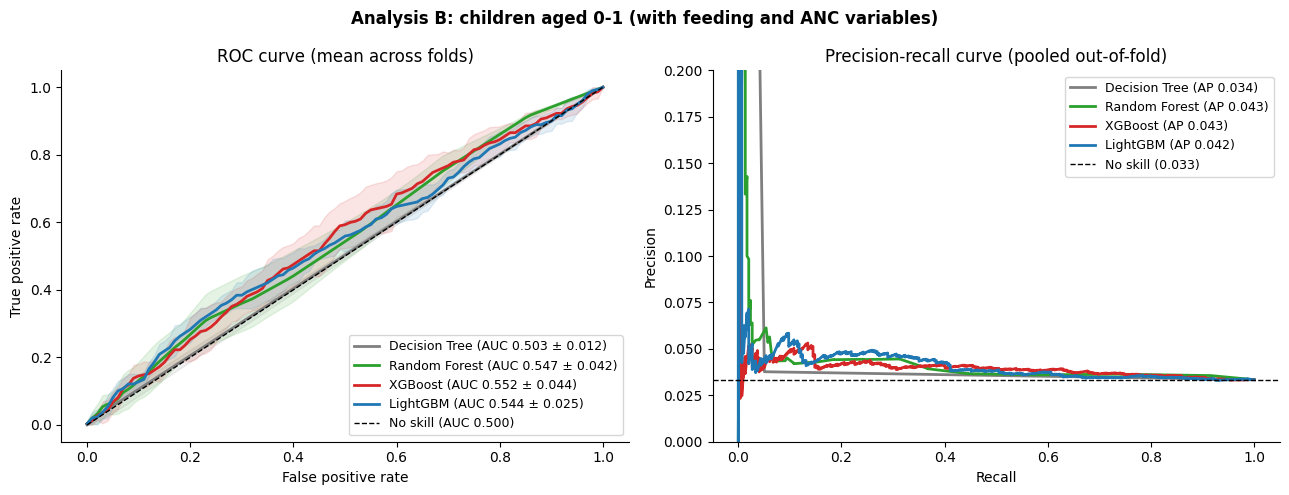

In [13]:
# Plot the mean ROC curve and the pooled out-of-fold precision-recall curve for the infant analysis.
plot_roc_pr(fold_inf, curves_inf, oof_inf, y_inf, 'Analysis B: children aged 0-1 (with feeding and ANC variables)', 'figures/ml_roc_pr_infants.png')

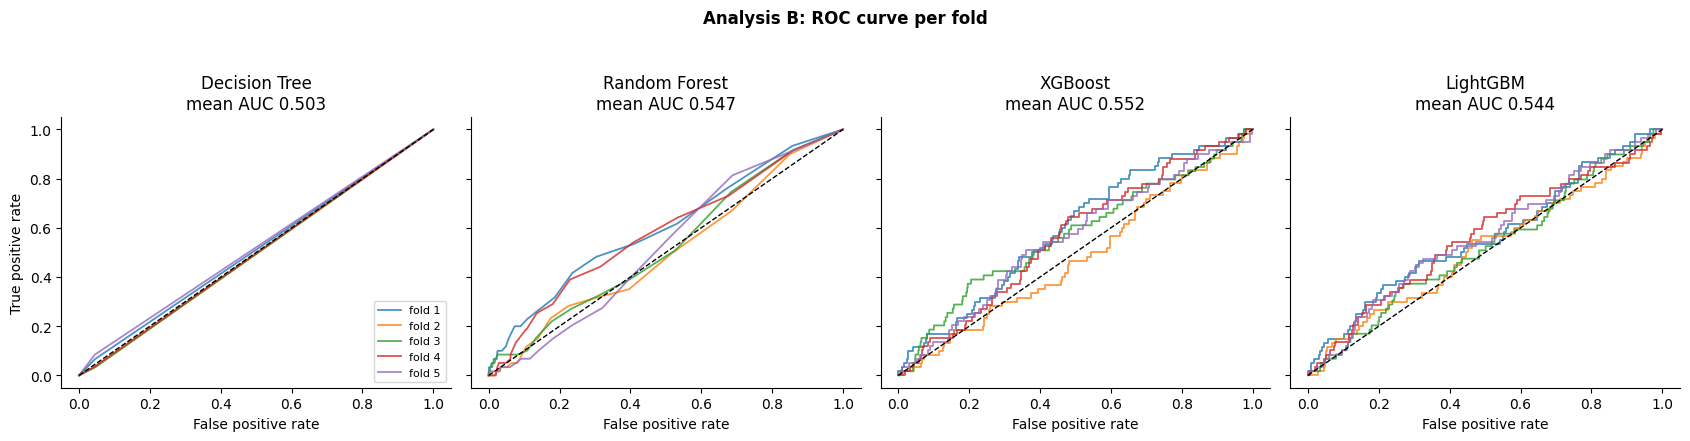

In [14]:
# Plot the ROC curve of every fold for each model in the infant analysis.
plot_fold_roc(fold_inf, curves_inf, 'Analysis B: ROC curve per fold', 'figures/ml_roc_folds_infants.png')

# Reference Checks

Two cheap checks put the tree-model scores in context. First, a **two-variable logistic regression** (child age and sex, the strongest signals from the earlier survey analysis) is cross-validated in exactly the same way; it is a reference only, not one of the four requested models. Second, a **label-permutation test** repeats the best model's cross-validation 50 times with the outcome shuffled, which shows how high the mean AUC gets by chance alone.

In [15]:
# Cross-validate simple logistic-regression references (child age only; child age + sex) with the same grouped folds.
from sklearn.linear_model import LogisticRegression

def cv_auc_simple(X, y, groups, cols):
    aucs = []
    for tr, te in cv.split(X, y, groups):
        lr = LogisticRegression(max_iter=1000).fit(X.iloc[tr][cols], y[tr])
        aucs.append(roc_auc_score(y[te], lr.predict_proba(X.iloc[te][cols])[:, 1]))
    return np.mean(aucs), np.std(aucs)

ref_rows = []
for label, X_, y_, g_ in [('A: all children', X_all, y_all, g_all), ('B: ages 0-1', X_inf, y_inf, g_inf)]:
    for cols in (['ub2'], ['ub2', 'female']):
        m_, s_ = cv_auc_simple(X_, y_, g_, cols)
        ref_rows.append({'analysis': label, 'reference model': 'Logistic regression: ' + ' + '.join(cols), 'ROC AUC': f'{m_:.3f} ± {s_:.3f}'})
ref_table = pd.DataFrame(ref_rows); print(ref_table.to_string(index=False))
ref_table.to_csv('outputs/ml_reference_logistic.csv', index=False)

       analysis                   reference model       ROC AUC
A: all children          Logistic regression: ub2 0.584 ± 0.025
A: all children Logistic regression: ub2 + female 0.588 ± 0.025
    B: ages 0-1          Logistic regression: ub2 0.542 ± 0.032
    B: ages 0-1 Logistic regression: ub2 + female 0.555 ± 0.040


In [16]:
# Run a 50-shuffle label-permutation test on the best model of each analysis to see what mean AUC chance alone produces.
def permutation_check(name, X, y, groups, observed, n_perm=50):
    rng = np.random.RandomState(RANDOM_STATE); null = []
    for _ in range(n_perm):
        yp = rng.permutation(y); aucs = []
        for tr, te in cv.split(X, yp, groups):
            m = clone(make_models()[name]).fit(X.iloc[tr], yp[tr])
            aucs.append(roc_auc_score(yp[te], m.predict_proba(X.iloc[te])[:, 1]))
        null.append(np.mean(aucs))
    null = np.array(null)
    return {'best model': name, 'observed mean AUC': round(observed, 3), 'chance mean AUC': round(null.mean(), 3),
            'chance SD': round(null.std(), 3), 'chance max': round(null.max(), 3), 'permutation p-value': round((1 + (null >= observed).sum()) / (n_perm + 1), 3)}

best_all = fold_all.groupby('model').roc_auc.mean().idxmax(); best_inf = fold_inf.groupby('model').roc_auc.mean().idxmax()
perm_rows = []
for label, name, X_, y_, g_, f_ in [('A: all children', best_all, X_all, y_all, g_all, fold_all), ('B: ages 0-1', best_inf, X_inf, y_inf, g_inf, fold_inf)]:
    r = permutation_check(name, X_, y_, g_, f_[f_.model == name].roc_auc.mean()); r['analysis'] = label; perm_rows.append(r)
perm_table = pd.DataFrame(perm_rows)[['analysis', 'best model', 'observed mean AUC', 'chance mean AUC', 'chance SD', 'chance max', 'permutation p-value']]
print(perm_table.to_string(index=False)); perm_table.to_csv('outputs/ml_permutation_check.csv', index=False)

       analysis best model  observed mean AUC  chance mean AUC  chance SD  chance max  permutation p-value
A: all children   LightGBM              0.542            0.499      0.016       0.533                0.020
    B: ages 0-1    XGBoost              0.552            0.497      0.026       0.563                0.039


# SHAP Analysis

SHAP values show how much each predictor pushes one child's predicted risk up or down. To keep the explanation honest, SHAP values are computed **out of fold**: within each cross-validation fold the best model (highest mean ROC AUC) is refitted on the training PSUs and explained on a random sample of held-out children, so the explanations come from data the model did not train on. SHAP values for the boosted models are on the log-odds scale (positive = higher predicted risk). A random subsample per fold (`SHAP_N_PER_FOLD`) keeps the computation light.

## Out-of-Fold SHAP Values

In [17]:
# Define helpers that compute out-of-fold SHAP values for the best model and summarize mean |SHAP| with direction of effect.
def positive_class(sv):
    if isinstance(sv, list): return sv[1]
    return sv[:, :, 1] if np.ndim(sv) == 3 else sv

def oof_shap(base, X, y, groups, n_per_fold=SHAP_N_PER_FOLD):
    rng = np.random.RandomState(RANDOM_STATE); sv_parts, x_parts = [], []
    for tr, te in cv.split(X, y, groups):
        model = clone(base).fit(X.iloc[tr], y[tr])
        pick = np.sort(rng.choice(te, size=min(n_per_fold, len(te)), replace=False))
        sv_parts.append(positive_class(shap.TreeExplainer(model).shap_values(X.iloc[pick]))); x_parts.append(X.iloc[pick])
    return np.vstack(sv_parts), pd.concat(x_parts)

def shap_table(sv, Xs):
    t = pd.DataFrame({'feature': Xs.columns, 'label': [str(variable_labels.get(c, ''))[:60] for c in Xs.columns],
                      'mean_abs_shap': np.abs(sv).mean(0)})
    t['share_%'] = (t.mean_abs_shap / t.mean_abs_shap.sum() * 100).round(1)
    # Direction: Spearman correlation between a feature's value and its SHAP value (+ = higher value raises risk).
    t['direction_rho'] = [round(spearmanr(Xs.iloc[:, i], sv[:, i], nan_policy='omit')[0], 2) if Xs.iloc[:, i].nunique() > 1 else np.nan for i in range(Xs.shape[1])]
    return t.sort_values('mean_abs_shap', ascending=False).reset_index(drop=True)

In [18]:
# Pick the best model for Analysis A by mean cross-validated ROC AUC and compute its out-of-fold SHAP values.
best_all = fold_all.groupby('model').roc_auc.mean().idxmax()
print('Best model, Analysis A:', best_all)
t0 = time.time()
sv_all, Xs_all = oof_shap(make_models()[best_all], X_all, y_all, g_all)
print(f'SHAP computed for {len(Xs_all):,} held-out children in {time.time() - t0:.0f} s')
shap_all = shap_table(sv_all, Xs_all)
shap_all.to_csv('outputs/ml_shap_importance_all_children.csv', index=False)
print(shap_all.head(12).to_string(index=False))

Best model, Analysis A: LightGBM


SHAP computed for 5,000 held-out children in 7 s
     feature                                            label  mean_abs_shap  share_%  direction_rho
         ub2                  Age of child in completed years       0.286593     17.4          -0.88
         wb4                          Age of mother/caretaker       0.216630     13.1           0.11
      wealth             Wealth index quintile (ordered, 1-5)       0.141197      8.6          -0.61
    division                                         Division       0.126265      7.6          -0.36
        cm11 Total number of live births (children ever born)       0.120112      7.3          -0.33
      female                                  Child is female       0.113919      6.9          -0.79
   water_cat                Drinking water source (collapsed)       0.111628      6.8          -0.67
    fuel_cat                          Cookstove fuel category       0.104904      6.4           0.15
   edu_level        Mother/caretaker educa

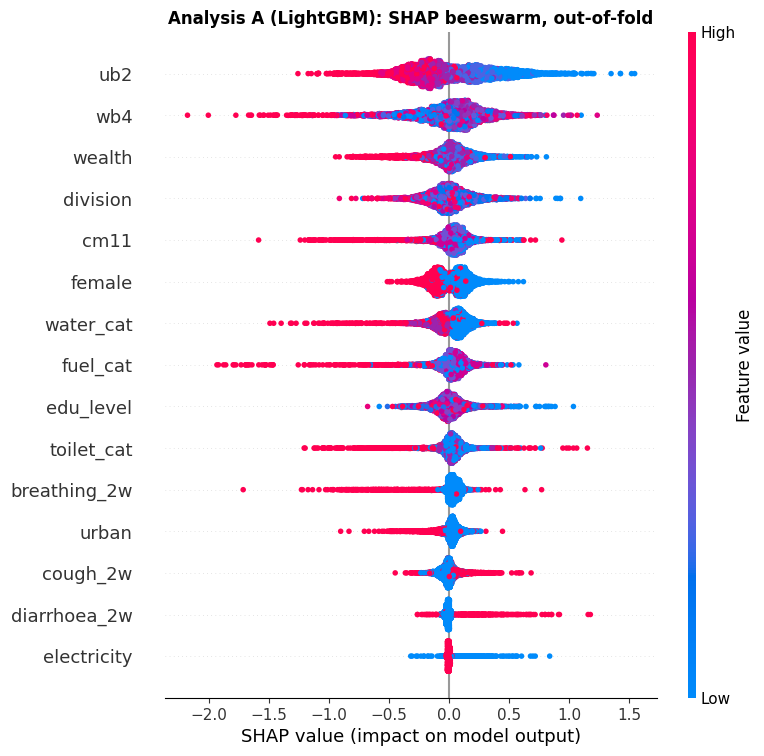

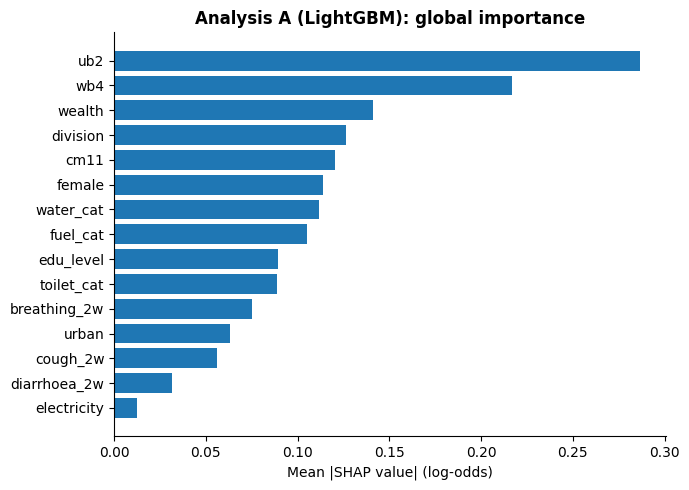

In [19]:
# Plot the SHAP beeswarm and the mean |SHAP| bar chart for Analysis A.
shap.summary_plot(sv_all, Xs_all, max_display=15, show=False)
plt.title(f'Analysis A ({best_all}): SHAP beeswarm, out-of-fold', fontweight='bold'); plt.savefig('figures/ml_shap_beeswarm_all_children.png', dpi=110, bbox_inches='tight'); plt.show()
fig, ax = plt.subplots(figsize=(7, 5)); top = shap_all.head(15)[::-1]
ax.barh(top.feature, top.mean_abs_shap, color='#1f77b4'); ax.set_xlabel('Mean |SHAP value| (log-odds)'); ax.set_title(f'Analysis A ({best_all}): global importance', fontweight='bold')
plt.tight_layout(); plt.savefig('figures/ml_shap_bar_all_children.png', dpi=110, bbox_inches='tight'); plt.show()

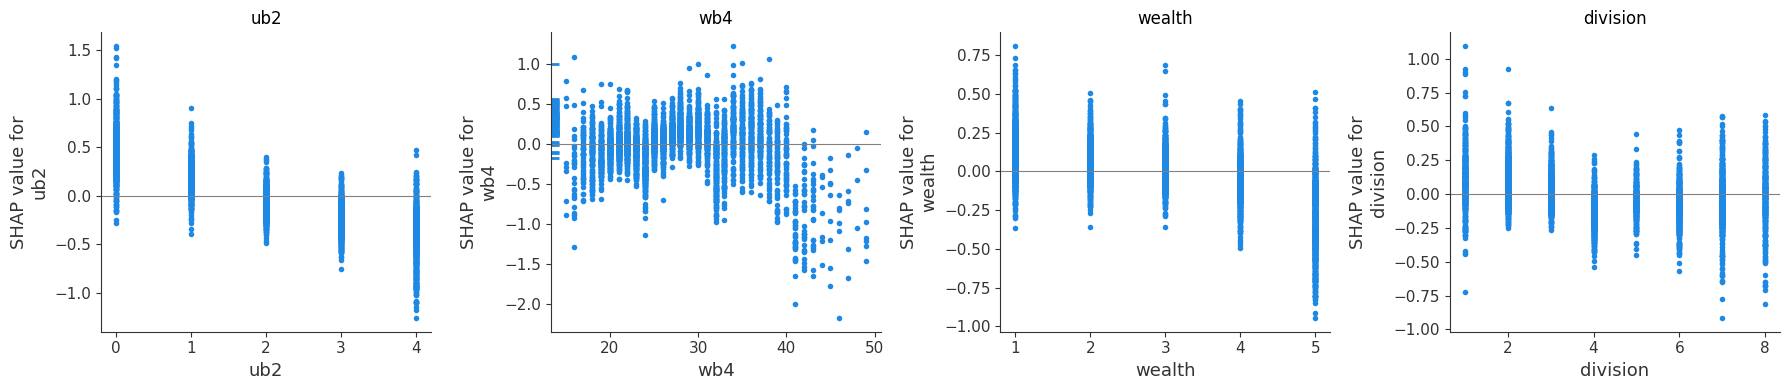

In [20]:
# Plot SHAP dependence plots for the four most important predictors in Analysis A.
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, f in zip(axes, shap_all.feature[:4]):
    shap.dependence_plot(f, sv_all, Xs_all, interaction_index=None, ax=ax, show=False)
    ax.set_title(f); ax.axhline(0, color='gray', lw=.8)
plt.tight_layout(); plt.savefig('figures/ml_shap_dependence_all_children.png', dpi=110, bbox_inches='tight'); plt.show()

In [21]:
# Pick the best model for Analysis B (ages 0-1), compute its out-of-fold SHAP values, and print the ranking.
best_inf = fold_inf.groupby('model').roc_auc.mean().idxmax()
print('Best model, Analysis B:', best_inf)
t0 = time.time()
sv_inf, Xs_inf = oof_shap(make_models()[best_inf], X_inf, y_inf, g_inf)
print(f'SHAP computed for {len(Xs_inf):,} held-out children in {time.time() - t0:.0f} s')
shap_inf = shap_table(sv_inf, Xs_inf)
shap_inf.to_csv('outputs/ml_shap_importance_infants.csv', index=False)
print(shap_inf.head(12).to_string(index=False))

Best model, Analysis B: XGBoost


SHAP computed for 5,000 held-out children in 3 s
  feature                                                      label  mean_abs_shap  share_%  direction_rho
      wb4                                    Age of mother/caretaker       0.449727     10.2           0.17
      dds Dietary diversity score (food groups eaten yesterday, 0-7)       0.351411      8.0          -0.44
 division                                                   Division       0.338003      7.6          -0.31
   wealth                       Wealth index quintile (ordered, 1-5)       0.306911      6.9          -0.61
 fg_flesh         Ate flesh foods yesterday (bd8i, bd8j, bd8k, bd8m)       0.252728      5.7          -0.77
  anc_cat               ANC visits category (children aged 0-1 only)       0.243473      5.5          -0.63
water_cat                          Drinking water source (collapsed)       0.234018      5.3          -0.70
edu_level                  Mother/caretaker education (ordered, 0-5)       0.223360    

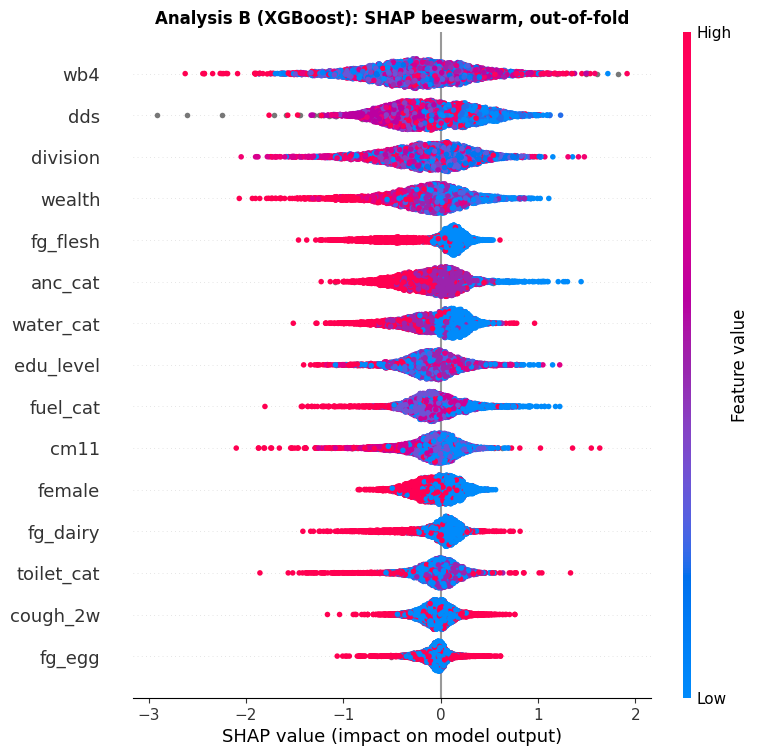

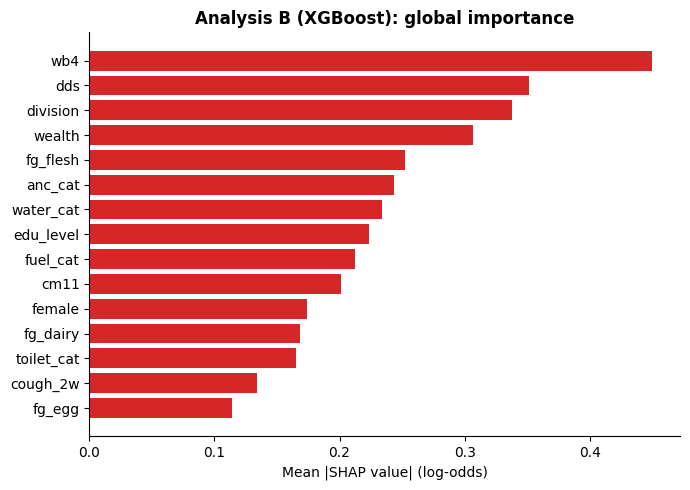

In [22]:
# Plot the SHAP beeswarm and the mean |SHAP| bar chart for Analysis B.
shap.summary_plot(sv_inf, Xs_inf, max_display=15, show=False)
plt.title(f'Analysis B ({best_inf}): SHAP beeswarm, out-of-fold', fontweight='bold'); plt.savefig('figures/ml_shap_beeswarm_infants.png', dpi=110, bbox_inches='tight'); plt.show()
fig, ax = plt.subplots(figsize=(7, 5)); top = shap_inf.head(15)[::-1]
ax.barh(top.feature, top.mean_abs_shap, color='#d62728'); ax.set_xlabel('Mean |SHAP value| (log-odds)'); ax.set_title(f'Analysis B ({best_inf}): global importance', fontweight='bold')
plt.tight_layout(); plt.savefig('figures/ml_shap_bar_infants.png', dpi=110, bbox_inches='tight'); plt.show()

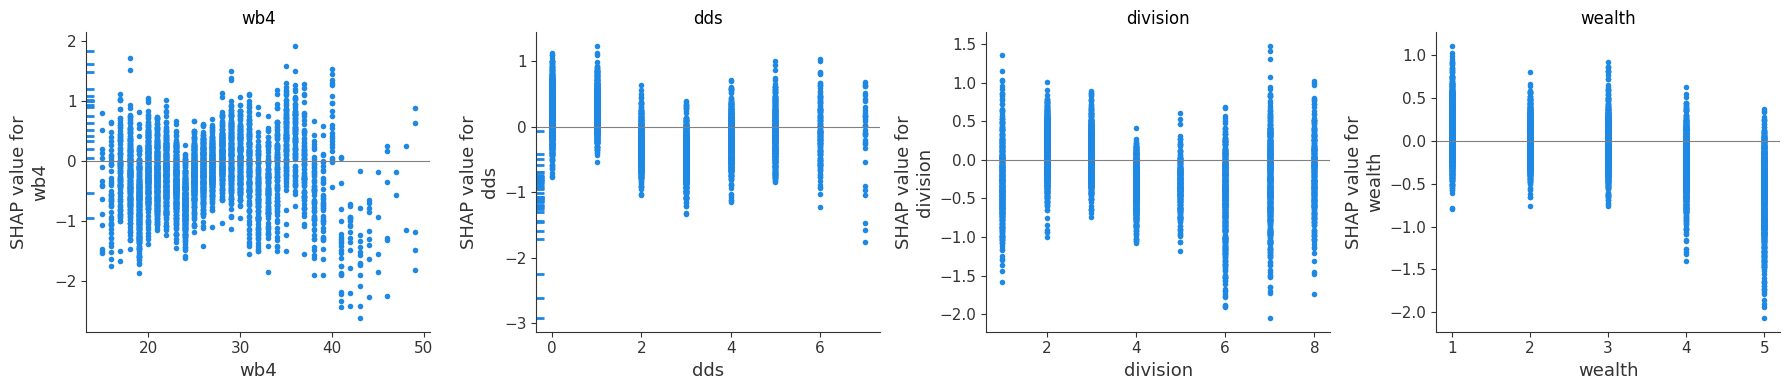

In [23]:
# Plot SHAP dependence plots for the four most important predictors in Analysis B.
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, f in zip(axes, shap_inf.feature[:4]):
    shap.dependence_plot(f, sv_inf, Xs_inf, interaction_index=None, ax=ax, show=False)
    ax.set_title(f); ax.axhline(0, color='gray', lw=.8)
plt.tight_layout(); plt.savefig('figures/ml_shap_dependence_infants.png', dpi=110, bbox_inches='tight'); plt.show()

In [24]:
# Check how much of the infant SHAP importance sits on the diet variables (dds and the food groups) versus the other predictors.
diet = ['dds', 'fg_grain', 'fg_legume', 'fg_dairy', 'fg_flesh', 'fg_egg', 'fg_vita', 'fg_ofv']
grp = {'Diet (dds + food groups)': diet, 'Breastfeeding / bottle': ['bf_status', 'bottle'], 'Antenatal care': ['anc_cat'],
       'Child age and sex': ['ub2', 'female'], 'Illness': ['diarrhoea_2w', 'cough_2w', 'breathing_2w']}
rest = [c for c in features_infant if c not in sum(grp.values(), [])]; grp['Household and maternal'] = rest
gs = pd.Series({k: shap_inf.set_index('feature').loc[v, 'mean_abs_shap'].sum() for k, v in grp.items()})
print((gs / gs.sum() * 100).round(1).sort_values(ascending=False).rename('share of total mean |SHAP| (%)').to_string())

Household and maternal      51.200001
Diet (dds + food groups)    26.700001
Illness                      6.700000
Child age and sex            6.500000
Antenatal care               5.500000
Breastfeeding / bottle       3.300000


# Summary of Findings

**Prediction (raw, untuned models; 5-fold PSU-grouped cross-validation)**
- All children (A): LightGBM is best with a mean ROC AUC of 0.542, then Random Forest 0.534, XGBoost 0.526 and Decision Tree 0.503 (chance = 0.500). Children aged 0-1 (B): XGBoost 0.552, Random Forest 0.547, LightGBM 0.544, Decision Tree 0.503.
- All models fit the training folds almost perfectly (train AUC 0.97-1.00) but barely beat chance on held-out PSUs, so the raw ensembles overfit. The default Decision Tree is no better than chance and has the worst Brier score (0.062 vs 0.025).
- Label-permutation tests give mean AUC 0.499 (SD 0.016) for A and 0.497 (SD 0.026) for B under chance, so the best models are statistically above chance (p = 0.020 and 0.039) but only just; the effect is far too small to be a usable screening tool. A two-variable logistic regression (child age + sex) scores 0.588 in A, better than every raw tree model.
- The top 10% highest-risk children contain only 12-15% of the cases (10% expected by chance).

**SHAP (out-of-fold, best model per analysis)**
- A (LightGBM): child age (17% of total mean |SHAP|), mother's age (13%), wealth (9%), division (8%), births (7%) and child sex (7%). Younger age, lower wealth, being male and recent cough or diarrhoea push predicted risk up.
- B (XGBoost): mother's age (10%), dietary diversity (8%), division (8%), wealth (7%), flesh foods (6%) and ANC (6%). The diet variables together account for about 27% of SHAP importance; lower diversity, no flesh foods and fewer ANC visits push risk up.
- The SHAP ranking agrees with the survey analysis on age, sex, wealth, diet and ANC. It disagrees on maternal age (`wb4`), which is not supported by the inference and probably reflects overfitting to a many-valued numeric variable.

Because the models are close to chance and overfit, SHAP here describes what these models learned, not reliable risk factors. See `SHAP_results.md` for tables, figures and caveats.

# Fair model comparison: survey-weighted logistic regression vs tuned ML

**Purpose.** The earlier results are not a fair comparison: the AUC of 0.635 reported in eda.ipynb is in-sample, while the tree-model AUCs in this notebook are PSU-grouped out-of-fold estimates. This section rebuilds the comparison using one shared set of children and identical outer folds for every model.

## Design decisions

- Each child is evaluated once using an outer 5-fold StratifiedGroupKFold, with every PSU (hh1) kept wholly inside one fold.
- For each analysis, every model uses the same outcome, rows, predictors, and outer folds. Missing predictors are imputed inside a scikit-learn pipeline; categorical predictors are one-hot encoded inside each training fold.
- Compare age + sex logistic regression, full unweighted logistic regression, full survey-weighted logistic regression, a more strongly regularized weighted logistic regression, and Decision Tree, Random Forest, XGBoost, and LightGBM.
- Tree hyperparameters are tuned only inside each outer training fold using 3-fold PSU-grouped inner CV. The outer test fold is never used for tuning.
- Weighted models use chweight as sample_weight. This is a weighted predictive fit, **not** a replacement for survey::svyglm or Stata svy: inference: this Python pipeline does not estimate design-based standard errors accounting for PSU and strata.
- Report pooled out-of-fold and fold-level ROC-AUC, average precision (PR-AUC), Brier score, and top-decile case capture, both weighted and unweighted. Calibration intercept and slope are also reported for pooled out-of-fold predictions.

**Interpretation rule:** do not compare these results to the old in-sample AUC as if they were equivalent. The fair comparison is the new out-of-fold results below. Because severe wasting is rare, ROC-AUC alone is insufficient; review PR-AUC, calibration, and top-decile capture too.

The full nested CV can take several minutes because tuning is repeated inside every outer fold.

**Tuning note:** the tree search uses unweighted ROC-AUC in the inner CV objective, while final outer-fold results include both weighted and unweighted metrics. This keeps model selection transparent and practical; if population-weighted tuning is required, implement a custom weighted scorer inside each inner fold before treating the selected hyperparameters as final.


In [ ]:
# Imports used only by the fair-comparison section.
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, SplineTransformer
from sklearn.model_selection import RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier

N_INNER_SPLITS = 3
N_TUNE_ITER = 4  # modest search budget to keep this practical on a laptop
NUMERIC_PREDICTORS = {'ub2', 'wb4', 'cm11', 'dds'}

def make_preprocessor(feature_names):
    """Fit imputation, age spline, scaling and category encoding inside each training fold."""
    age_cols = ['ub2'] if 'ub2' in feature_names else []
    numeric_cols = [c for c in feature_names if c in NUMERIC_PREDICTORS and c not in age_cols]
    categorical_cols = [c for c in feature_names if c not in NUMERIC_PREDICTORS]

    transformers = []
    if age_cols:
        age_pipe = Pipeline([
            ('impute', SimpleImputer(strategy='median')),
            ('spline', SplineTransformer(n_knots=4, degree=2, include_bias=False))
        ])
        transformers.append(('age_spline', age_pipe, age_cols))
    if numeric_cols:
        numeric_pipe = Pipeline([
            ('impute', SimpleImputer(strategy='median')),
            ('scale', StandardScaler())
        ])
        transformers.append(('numeric', numeric_pipe, numeric_cols))
    if categorical_cols:
        categorical_pipe = Pipeline([
            ('impute', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ])
        transformers.append(('categorical', categorical_pipe, categorical_cols))
    return ColumnTransformer(transformers=transformers, remainder='drop')

def build_model_specs(all_features):
    """Model factory specifications; tree search is nested inside the outer PSU folds."""
    simple_features = [c for c in ['ub2', 'female'] if c in all_features]
    return {
        'Prevalence baseline': {
            'features': all_features, 'estimator': DummyClassifier(strategy='prior'),
            'weighted_fit': True, 'search': None
        },
        'Logistic: age + sex': {
            'features': simple_features,
            'estimator': LogisticRegression(C=1.0, max_iter=3000, solver='lbfgs'),
            'weighted_fit': False, 'search': None
        },
        'Logistic: full, unweighted': {
            'features': all_features,
            'estimator': LogisticRegression(C=1.0, max_iter=3000, solver='lbfgs'),
            'weighted_fit': False, 'search': None
        },
        'Logistic: full, survey-weighted': {
            'features': all_features,
            'estimator': LogisticRegression(C=1.0, max_iter=3000, solver='lbfgs'),
            'weighted_fit': True, 'search': None
        },
        'Logistic: regularized, survey-weighted': {
            'features': all_features,
            'estimator': LogisticRegression(C=0.1, max_iter=3000, solver='lbfgs'),
            'weighted_fit': True, 'search': None
        },
        'Decision Tree (tuned)': {
            'features': all_features, 'estimator': DecisionTreeClassifier(random_state=RANDOM_STATE),
            'weighted_fit': True, 'search': {
                'model__max_depth': [3, 5, 8, None],
                'model__min_samples_leaf': [10, 25, 50],
                'model__criterion': ['gini', 'entropy']
            }
        },
        'Random Forest (tuned)': {
            'features': all_features, 'estimator': RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=N_JOBS),
            'weighted_fit': True, 'search': {
                'model__n_estimators': [150, 300],
                'model__max_depth': [5, 10, None],
                'model__min_samples_leaf': [10, 25],
                'model__max_features': ['sqrt', 0.7]
            }
        },
        'XGBoost (tuned)': {
            'features': all_features,
            'estimator': XGBClassifier(random_state=RANDOM_STATE, n_jobs=N_JOBS, eval_metric='logloss', tree_method='hist'),
            'weighted_fit': True, 'search': {
                'model__n_estimators': [150, 300],
                'model__max_depth': [2, 3],
                'model__learning_rate': [0.03, 0.08],
                'model__min_child_weight': [5, 10],
                'model__subsample': [0.8, 1.0],
                'model__colsample_bytree': [0.7, 1.0],
                'model__reg_lambda': [1.0, 5.0]
            }
        },
        'LightGBM (tuned)': {
            'features': all_features,
            'estimator': LGBMClassifier(random_state=RANDOM_STATE, n_jobs=N_JOBS, verbosity=-1),
            'weighted_fit': True, 'search': {
                'model__n_estimators': [150, 300],
                'model__max_depth': [-1, 3, 5],
                'model__num_leaves': [7, 15, 31],
                'model__learning_rate': [0.03, 0.08],
                'model__min_child_samples': [20, 50],
                'model__reg_lambda': [1.0, 5.0]
            }
        }
    }

def safe_calibration(y_true, probability, sample_weight=None):
    """Calibration intercept/slope from outcome regressed on logit(predicted risk)."""
    clipped = np.clip(probability, 1e-6, 1 - 1e-6)
    logit_p = np.log(clipped / (1 - clipped)).reshape(-1, 1)
    try:
        cal = LogisticRegression(C=1e6, max_iter=2000, solver='lbfgs')
        cal.fit(logit_p, y_true, sample_weight=sample_weight)
        return float(cal.intercept_[0]), float(cal.coef_[0, 0])
    except Exception:
        return np.nan, np.nan

def prediction_metrics(y_true, probability, sample_weight):
    """Metrics for one prediction set, reported with and without survey weights."""
    y_true = np.asarray(y_true, dtype=int)
    probability = np.asarray(probability, dtype=float)
    sample_weight = np.asarray(sample_weight, dtype=float)
    top_n = max(1, int(np.ceil(0.10 * len(y_true))))
    top_idx = np.argsort(-probability, kind='mergesort')[:top_n]
    weighted_case_total = np.sum(sample_weight * y_true)
    weighted_top_capture = (np.sum(sample_weight[top_idx] * y_true[top_idx]) / weighted_case_total
                            if weighted_case_total > 0 else np.nan)
    return {
        'roc_auc_unweighted': roc_auc_score(y_true, probability),
        'roc_auc_weighted': roc_auc_score(y_true, probability, sample_weight=sample_weight),
        'pr_auc_unweighted': average_precision_score(y_true, probability),
        'pr_auc_weighted': average_precision_score(y_true, probability, sample_weight=sample_weight),
        'brier_unweighted': brier_score_loss(y_true, probability),
        'brier_weighted': np.average((y_true - probability) ** 2, weights=sample_weight),
        'top10_capture_unweighted': (y_true[top_idx].sum() / y_true.sum()) if y_true.sum() else np.nan,
        'top10_capture_weighted': weighted_top_capture
    }

def run_nested_grouped_comparison(X, y, groups, weights, feature_names, analysis_label):
    """Shared outer PSU folds; tune tree models on inner PSU folds only."""
    y = np.asarray(y, dtype=int)
    groups = np.asarray(groups)
    weights = np.asarray(weights, dtype=float)
    if np.any(~np.isfinite(weights)) or np.any(weights <= 0):
        raise ValueError('Survey weights must be finite and positive after data cleaning.')
    outer_cv = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
    outer_splits = list(outer_cv.split(X, y, groups))
    for fold_no, (tr, te) in enumerate(outer_splits, start=1):
        if set(groups[tr]).intersection(set(groups[te])):
            raise AssertionError(f'PSU leakage detected in outer fold {fold_no}.')
        if y[te].sum() == 0:
            raise ValueError(f'Outer fold {fold_no} has no severe-wasting cases; revise grouped folds.')

    specs = build_model_specs(feature_names)
    oof = {name: np.full(len(y), np.nan, dtype=float) for name in specs}
    fold_rows, tuning_rows = [], []

    for model_name, spec in specs.items():
        print(f'[{analysis_label}] {model_name}')
        used_features = spec['features']
        X_model = X[used_features].copy()
        for fold_no, (tr, te) in enumerate(outer_splits, start=1):
            X_tr, X_te = X_model.iloc[tr], X_model.iloc[te]
            y_tr, y_te = y[tr], y[te]
            w_tr, w_te = weights[tr], weights[te]
            pipeline = Pipeline([
                ('preprocess', make_preprocessor(used_features)),
                ('model', clone(spec['estimator']))
            ])
            fit_start = time.time()
            if spec['search']:
                inner_cv = StratifiedGroupKFold(n_splits=N_INNER_SPLITS, shuffle=True,
                                                random_state=RANDOM_STATE + fold_no)
                inner_splits = list(inner_cv.split(X_tr, y_tr, groups[tr]))
                search = RandomizedSearchCV(
                    estimator=pipeline,
                    param_distributions=spec['search'],
                    n_iter=N_TUNE_ITER,
                    scoring='roc_auc',
                    cv=inner_splits,
                    refit=True,
                    n_jobs=1,
                    random_state=RANDOM_STATE + fold_no,
                    error_score='raise',
                    return_train_score=False
                )
                if spec['weighted_fit']:
                    search.fit(X_tr, y_tr, model__sample_weight=w_tr)
                else:
                    search.fit(X_tr, y_tr)
                fitted = search.best_estimator_
                tuning_rows.append({
                    'analysis': analysis_label, 'model': model_name, 'fold': fold_no,
                    'best_inner_cv_auc_unweighted': search.best_score_,
                    'best_parameters': str(search.best_params_)
                })
            else:
                fitted = pipeline
                if spec['weighted_fit']:
                    fitted.fit(X_tr, y_tr, model__sample_weight=w_tr)
                else:
                    fitted.fit(X_tr, y_tr)
            fit_seconds = time.time() - fit_start
            p_te = fitted.predict_proba(X_te)[:, 1]
            oof[model_name][te] = p_te
            metrics = prediction_metrics(y_te, p_te, w_te)
            fold_rows.append({
                'analysis': analysis_label, 'model': model_name, 'fold': fold_no,
                'n_test': len(te), 'cases_test': int(y_te.sum()),
                'fit_seconds': fit_seconds, **metrics
            })

    if any(np.isnan(p).any() for p in oof.values()):
        raise AssertionError('Some observations do not have exactly one out-of-fold prediction.')
    fold_df = pd.DataFrame(fold_rows)
    tuning_df = pd.DataFrame(tuning_rows)
    summary_rows = []
    for model_name, probability in oof.items():
        pooled = prediction_metrics(y, probability, weights)
        cal_int, cal_slope = safe_calibration(y, probability)
        w_cal_int, w_cal_slope = safe_calibration(y, probability, sample_weight=weights)
        row = {
            'analysis': analysis_label, 'model': model_name, 'n': len(y), 'cases': int(y.sum()),
            'prevalence_unweighted': float(y.mean()),
            'prevalence_weighted': float(np.average(y, weights=weights)),
            **{f'pooled_{k}': v for k, v in pooled.items()},
            'calibration_intercept_unweighted': cal_int, 'calibration_slope_unweighted': cal_slope,
            'calibration_intercept_weighted': w_cal_int, 'calibration_slope_weighted': w_cal_slope
        }
        model_folds = fold_df[fold_df.model == model_name]
        for metric in ['roc_auc_unweighted', 'roc_auc_weighted', 'pr_auc_unweighted', 'pr_auc_weighted',
                       'brier_unweighted', 'brier_weighted', 'top10_capture_unweighted', 'top10_capture_weighted']:
            row[f'fold_mean_{metric}'] = model_folds[metric].mean()
            row[f'fold_sd_{metric}'] = model_folds[metric].std(ddof=1)
        summary_rows.append(row)
    summary_df = pd.DataFrame(summary_rows).sort_values('pooled_roc_auc_weighted', ascending=False)
    return summary_df, fold_df, tuning_df, pd.DataFrame({'y_true': y, 'psu': groups, 'survey_weight': weights, **oof})

print('Fair-comparison pipeline defined. Run the next cell to execute nested CV.')

In [ ]:
# Run identical nested PSU-grouped comparisons for all children and the under-2 subgroup.
# These are new results; use them instead of the old in-sample-vs-cross-validation comparison.
weights_all = df_all['chweight'].to_numpy(dtype=float)
weights_inf = df_infant['chweight'].to_numpy(dtype=float)

t0 = time.time()
fair_summary_all, fair_folds_all, fair_tuning_all, fair_oof_all = run_nested_grouped_comparison(
    X_all, y_all, g_all, weights_all, features_all, 'A: all children'
)
print(f'\nAnalysis A finished in {(time.time() - t0) / 60:.1f} minutes')
display(fair_summary_all.round(4))

t0 = time.time()
fair_summary_inf, fair_folds_inf, fair_tuning_inf, fair_oof_inf = run_nested_grouped_comparison(
    X_inf, y_inf, g_inf, weights_inf, features_infant, 'B: children aged 0-1'
)
print(f'\nAnalysis B finished in {(time.time() - t0) / 60:.1f} minutes')
display(fair_summary_inf.round(4))

# Persist detailed outputs so the comparison can be inspected without rerunning nested CV.
fair_summary_all.to_csv('outputs/fair_model_comparison_summary_all_children.csv', index=False)
fair_folds_all.to_csv('outputs/fair_model_comparison_folds_all_children.csv', index=False)
fair_tuning_all.to_csv('outputs/fair_model_comparison_tuning_all_children.csv', index=False)
fair_oof_all.to_csv('outputs/fair_model_comparison_oof_all_children.csv', index=False)
fair_summary_inf.to_csv('outputs/fair_model_comparison_summary_under2.csv', index=False)
fair_folds_inf.to_csv('outputs/fair_model_comparison_folds_under2.csv', index=False)
fair_tuning_inf.to_csv('outputs/fair_model_comparison_tuning_under2.csv', index=False)
fair_oof_inf.to_csv('outputs/fair_model_comparison_oof_under2.csv', index=False)
print('Saved 8 CSV files under outputs/.')

# How to interpret the fair comparison

Use the pooled out-of-fold columns as the primary model comparison; fold means and SDs show stability across held-out PSUs.

1. **Primary discrimination metric:** compare pooled_roc_auc_weighted across models because the intended target is population-relevant prediction. Also report pooled_roc_auc_unweighted so the result is transparent about the estimand.
2. **Rare-outcome metric:** compare weighted and unweighted PR-AUC with the corresponding outcome prevalence. PR-AUC values close to prevalence indicate little practical ranking skill.
3. **Probability quality:** lower Brier scores are better. Calibration intercept near 0 and slope near 1 are desirable; a slope well below 1 often indicates overly extreme predictions.
4. **Screening usefulness:** top10_capture_weighted is the fraction of survey-weighted severe-wasting cases captured among the 10% of children with the highest predicted risk. Compare it with 0.10 as the random-ranking reference.
5. **Tuning leakage:** inspect the tuning CSV. Inner CV selects hyperparameters using only each outer training fold; the outer-fold metrics remain the evaluation estimates.
6. **Do not select a model from AUC alone.** Prefer a simpler model if its weighted out-of-fold discrimination and calibration are practically similar to a tuned ensemble.
7. **No causal claims:** predictive importance does not establish that a characteristic causes severe wasting. For inferential associations, retain the survey-design analysis and validate its estimates against Stata svy: or R survey before final reporting.

## Important limitations

- The nested grouped CV is a more defensible internal validation design, not an external validation study.
- chweight is used as a predictive sample weight; this Python implementation does not calculate design-based standard errors using both hh1 and strata.
- The fold assignment is stratified by the observed outcome while grouped by PSU. If some PSUs contain many cases, fold case counts may still differ; check the saved fold metrics.
- The tuned trees are intentionally given a small search budget for laptop practicality. If the winner is sensitive to random seeds or fold assignment, increase the search budget or use repeated grouped CV before making a strong claim.
- This section requires the same MICS-child-ISRC.dta and Python packages used by the earlier notebook. The repository-side edit has not executed the analysis against your local dataset; run the cells in order to generate the CSV outputs.

## Cluster-level uncertainty and paired comparisons

To avoid treating children from the same primary sampling unit as independent, this section bootstraps entire PSUs from the out-of-fold predictions. It estimates confidence intervals for weighted AUC and paired AUC differences relative to the survey-weighted logistic model. These intervals are conditional on the out-of-fold predictions; they do not capture every source of model-selection or fold-assignment uncertainty.

In [ ]:
# Cluster bootstrap uncertainty for pooled out-of-fold weighted AUC.
# This resamples whole PSUs, not individual children, and compares models on paired resamples.
# Run after the preceding nested-CV cell has completed.
N_CLUSTER_BOOTSTRAPS = 300
BOOTSTRAP_SEED = RANDOM_STATE + 100

def cluster_bootstrap_auc_differences(oof_df, model_names, outcome_col='y_true',
                                      group_col='psu', weight_col='survey_weight',
                                      n_boot=N_CLUSTER_BOOTSTRAPS, seed=BOOTSTRAP_SEED):
    rng = np.random.RandomState(seed)
    y = oof_df[outcome_col].to_numpy(dtype=int)
    groups = oof_df[group_col].to_numpy()
    weights = oof_df[weight_col].to_numpy(dtype=float)
    probs = {name: oof_df[name].to_numpy(dtype=float) for name in model_names}
    unique_groups = pd.unique(groups)
    rows = []
    # Include weighted AUC for each model and paired differences versus weighted logistic regression.
    reference = 'Logistic: full, survey-weighted'
    for b in range(n_boot):
        sampled_groups = rng.choice(unique_groups, size=len(unique_groups), replace=True)
        # Preserve cluster multiplicity by concatenating every sampled PSU's records.
        indices = np.concatenate([np.flatnonzero(groups == group) for group in sampled_groups])
        y_b, w_b = y[indices], weights[indices]
        if np.unique(y_b).size < 2:
            continue
        aucs = {}
        for name in model_names:
            try:
                aucs[name] = roc_auc_score(y_b, probs[name][indices], sample_weight=w_b)
            except ValueError:
                aucs[name] = np.nan
        for name, auc in aucs.items():
            rows.append({'bootstrap': b, 'model': name, 'weighted_auc': auc,
                         'difference_vs_weighted_logistic': auc - aucs.get(reference, np.nan)})
    boot = pd.DataFrame(rows)
    summary = []
    for name in model_names:
        part = boot[boot.model == name]
        valid_auc = part.weighted_auc.dropna()
        valid_diff = part.difference_vs_weighted_logistic.dropna()
        summary.append({
            'model': name,
            'weighted_auc_point_estimate': roc_auc_score(
                oof_df[outcome_col], oof_df[name], sample_weight=oof_df[weight_col]),
            'cluster_bootstrap_auc_ci_low': valid_auc.quantile(0.025),
            'cluster_bootstrap_auc_ci_high': valid_auc.quantile(0.975),
            'difference_vs_weighted_logistic_point': (
                roc_auc_score(oof_df[outcome_col], oof_df[name], sample_weight=oof_df[weight_col])
                - roc_auc_score(oof_df[outcome_col], oof_df[reference], sample_weight=oof_df[weight_col])
            ),
            'difference_ci_low': valid_diff.quantile(0.025),
            'difference_ci_high': valid_diff.quantile(0.975),
            'successful_bootstraps': int(valid_diff.shape[0])
        })
    return pd.DataFrame(summary).sort_values('weighted_auc_point_estimate', ascending=False), boot

# Paired cluster-bootstrap intervals for the all-children analysis.
bootstrap_summary_all, bootstrap_draws_all = cluster_bootstrap_auc_differences(
    fair_oof_all, list(fair_oof_all.columns.drop(['y_true', 'psu', 'survey_weight']))
)
display(bootstrap_summary_all.round(4))
bootstrap_summary_all.to_csv('outputs/fair_model_comparison_cluster_bootstrap_all_children.csv', index=False)

# Repeat for children aged under 2.
bootstrap_summary_inf, bootstrap_draws_inf = cluster_bootstrap_auc_differences(
    fair_oof_inf, list(fair_oof_inf.columns.drop(['y_true', 'psu', 'survey_weight']))
)
display(bootstrap_summary_inf.round(4))
bootstrap_summary_inf.to_csv('outputs/fair_model_comparison_cluster_bootstrap_under2.csv', index=False)

print('Intervals describe uncertainty from resampling PSUs conditional on the saved out-of-fold predictions.')
print('They do not include all uncertainty from model fitting, tuning, or choice of CV partition.')